# Previsão de Avaliações de Filmes no Dataset MovieLens

Este projeto tem como objetivo prever a avaliação (*rating*) que um utilizador atribuiria a um determinado filme, com base no histórico de avaliações e nos géneros cinematográficos do dataset **MovieLens (`ml-latest-small`)**. Para tal, são comparados dois algoritmos de aprendizagem supervisionada de regressão: **Regressão Ridge** e **Árvore de Decisão**.

### 1 - Carregamento e Exploração de Dados (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings = pd.read_csv("ratings.csv")
movies = pd.read_csv("movies.csv")

display(ratings.head())
display(movies.head())

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [2]:
print("Dimensão da tabela ratings (linhas, colunas):", ratings.shape)
print("Dimensão da tabela movies (linhas, colunas):", movies.shape)
print("-" * 45)
print("Número total de avaliações:", len(ratings))
print("Número de utilizadores únicos:", ratings["userId"].nunique())
print("Número de filmes no catálogo:", len(movies))
print("Número de filmes avaliados:", ratings["movieId"].nunique())

Dimensão da tabela ratings (linhas, colunas): (100836, 4)
Dimensão da tabela movies (linhas, colunas): (9742, 3)
---------------------------------------------
Número total de avaliações: 100836
Número de utilizadores únicos: 610
Número de filmes no catálogo: 9742
Número de filmes avaliados: 9724


#### 1.1 - Caracterização e Tipos dos Atributos

Abaixo inspecionam-se os tipos primitivos detetados pelo `pandas` em ambos os ficheiros e caracteriza-se a natureza estatística de cada coluna:

In [3]:
print("Tipos de dados na tabela ratings:")
display(ratings.dtypes.to_frame(name="Tipo de Dado (dtype)"))

print("Tipos de dados na tabela movies:")
display(movies.dtypes.to_frame(name="Tipo de Dado (dtype)"))

Tipos de dados na tabela ratings:


,Tipo de Dado (dtype)
userId,int64
movieId,int64
rating,float64
timestamp,int64


Tipos de dados na tabela movies:


,Tipo de Dado (dtype)
movieId,int64
title,str
genres,str


**Descrição detalhada dos atributos:**
* **`userId`** (`int64` originalmente, convertido para `str`): **Atributo categórico nominal**. Identifica de forma única e anónima cada utilizador (de 1 a 610). Embora codificado com algarismos, não possui relação de ordem nem grandeza matemática.
* **`movieId`** (`int64` originalmente, convertido para `str`): **Atributo categórico nominal**. Identificador único de cada filme no catálogo MovieLens.
* **`rating`** (`float64`): **Variável-alvo numérica (escala contínua/discreta ordenada)**. Representa a avaliação atribuída pelo utilizador numa escala de $0.5$ a $5.0$ estrelas, com incrementos de $0.5$ estrelas.
* **`timestamp`** (`int64`): **Atributo numérico temporal**. Representa o momento da avaliação em segundos desde 1 de janeiro de 1970 (UTC). Não será incluído como variável preditora nesta modelação para focar a aprendizagem na relação estática entre utilizador, filme e géneros.
* **`title`** (`object` / `string`): **Atributo textual descritivo**. Contém o título do filme e o ano de lançamento entre parênteses. É utilizado para interpretação e visualização dos resultados.
* **`genres`** (`object` / `string`): **Atributo categórico multirrótulo**. Lista de géneros cinematográficos associados a cada filme, separados pelo carácter `|` (ex.: `Action|Adventure|Sci-Fi`).

#### 1.2 - Distribuição da Variável-Alvo (`rating`)

Para compreender o comportamento das avaliações antes da modelação, analisam-se as estatísticas descritivas e a distribuição de frequências da variável-alvo `rating`:

Estatísticas descritivas da variável-alvo (rating):


,Estatísticas
count,100836.000
mean,3.502
std,1.043
min,0.500
25%,3.000
50%,3.500
75%,4.000
max,5.000


,Frequência Absoluta,Percentagem (%)
rating,,
0.5,1370,1.36
1.0,2811,2.79
1.5,1791,1.78
2.0,7551,7.49
2.5,5550,5.50
3.0,20047,19.88
3.5,13136,13.03
4.0,26818,26.60
4.5,8551,8.48


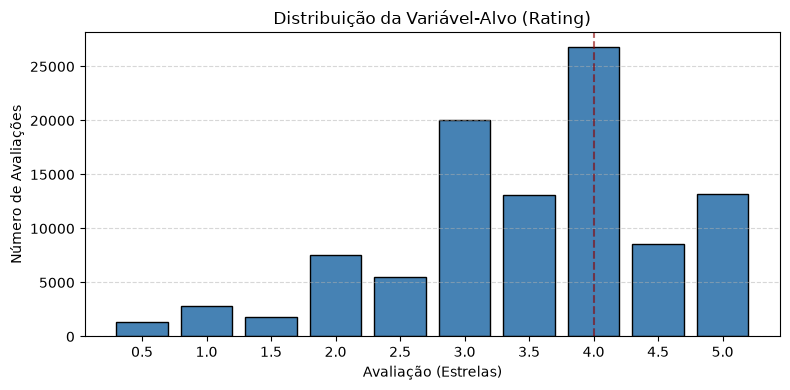

In [4]:
print("Estatísticas descritivas da variável-alvo (rating):")
display(ratings["rating"].describe().to_frame(name="Estatísticas").round(3))

contagem_notas = ratings["rating"].value_counts().sort_index()
percentagem_notas = (ratings["rating"].value_counts(normalize=True).sort_index() * 100).round(2)

tabela_distribuicao = pd.DataFrame({
    "Frequência Absoluta": contagem_notas,
    "Percentagem (%)": percentagem_notas
})
display(tabela_distribuicao)

plt.figure(figsize=(8, 4))
plt.bar(contagem_notas.index.astype(str), contagem_notas.values, color="steelblue", edgecolor="black")
plt.axvline(x=str(4.0), color="darkred", linestyle="--", alpha=0.6, label=f"Média: {ratings['rating'].mean():.2f}")
plt.title("Distribuição da Variável-Alvo (Rating)")
plt.xlabel("Avaliação (Estrelas)")
plt.ylabel("Número de Avaliações")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Análise da distribuição:**
* A média das avaliações situa-se em **3,502 estrelas** (com desvio-padrão de **1,043**) e a mediana (percentil 50%) é de **3,5 estrelas**.
* Verifica-se uma **assimetria negativa** (maior concentração de avaliações entre `3.0` e `5.0` estrelas), fenómeno típico em sistemas de recomendação onde os utilizadores tendem a escolher assistir a filmes dos quais já esperam gostar.
* Os utilizadores atribuem com muito maior frequência notas inteiras (`4.0`, `3.0`, `5.0`) do que notas fracionadas (`0.5`, `1.5`, `2.5`, `3.5`, `4.5`).

### 2 - Junção das Tabelas e Verificação de Valores em Falta

In [5]:
avaliacoes = ratings.merge(
    movies,
    on="movieId",
    how="left",
    validate="many_to_one"
)

display(avaliacoes[["userId", "title", "genres", "rating"]].head(10))

,userId,title,genres,rating
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,4.0
1,1,Grumpier Old Men (1995),Comedy|Romance,4.0
2,1,Heat (1995),Action|Crime|Thriller,4.0
3,1,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,5.0
4,1,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.0
5,1,From Dusk Till Dawn (1996),Action|Comedy|Horror|Thriller,3.0
6,1,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance,5.0
7,1,Braveheart (1995),Action|Drama|War,4.0
8,1,Rob Roy (1995),Action|Drama|Romance|War,5.0
9,1,Canadian Bacon (1995),Comedy|War,5.0


Apresentam-se as primeiras dez avaliações, associadas aos respetivos títulos e géneros dos filmes. Neste conjunto de dados, estas linhas iniciais correspondem ao utilizador 1.

**Observação**: o método `.head(x)` seleciona os primeiros `x` registos do DataFrame Pandas.

#### 2.1 - Verificação de Valores em Falta (Missing Values)

Verifica-se a existência de valores nulos (`NaN`) nas tabelas originais (`ratings` e `movies`) e na tabela resultante da junção (`avaliacoes`):

In [6]:
print("1) Valores em falta em ratings:")
print(ratings.isna().sum(), "\n")

print("2) Valores em falta em movies:")
print(movies.isna().sum(), "\n")

print("3) Valores em falta após a junção (avaliacoes):")
print(avaliacoes.isna().sum())

1) Valores em falta em ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64 

2) Valores em falta em movies:
movieId    0
title      0
genres     0
dtype: int64 

3) Valores em falta após a junção (avaliacoes):
userId       0
movieId      0
rating       0
timestamp    0
title        0
genres       0
dtype: int64


Confirma-se que **não existem valores em falta (0 registos nulos)** em nenhuma das tabelas nem após o `merge`, garantindo integridade referencial completa para todos os 100.836 registos.

*Analisando cenários:*
Caso se queira explorar os filmes avaliados especificamente pelo `userId` 1:

In [7]:
avaliacoes_user1 = avaliacoes.loc[
    avaliacoes["userId"] == 1,
    ["title", "genres", "rating"]
]

print("Número de filmes avaliados pelo utilizador 1:", len(avaliacoes_user1))
display(avaliacoes_user1.head(10))

Número de filmes avaliados pelo utilizador 1: 232


,title,genres,rating
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,4.0
1,Grumpier Old Men (1995),Comedy|Romance,4.0
2,Heat (1995),Action|Crime|Thriller,4.0
3,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,5.0
4,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.0
5,From Dusk Till Dawn (1996),Action|Comedy|Horror|Thriller,3.0
6,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance,5.0
7,Braveheart (1995),Action|Drama|War,4.0
8,Rob Roy (1995),Action|Drama|Romance|War,5.0
9,Canadian Bacon (1995),Comedy|War,5.0


### 3 - Formulação do Problema e Divisão Treino/Teste

**Identificação e Justificação da Técnica (Regressão Supervisionada):**
O problema consiste em prever uma variável quantitativa (`rating`) a partir de exemplos históricos rotulados, configurando uma tarefa de **Aprendizagem Supervisionada de Regressão**. A escolha de **Regressão** (em detrimento de Classificação Multiclasse) justifica-se pelo facto de as notas possuírem uma relação métrica e ordinal contínua no intervalo $[0.5, 5.0]$: o erro cometido ao prever `4.5` para uma nota real de `5.0` ($vert{}5.0 - 4.5vert{} = 0.5$) é substancialmente inferior ao erro de prever `1.0` ($vert{}5.0 - 1.0vert{} = 4.0$). Os modelos de regressão otimizam diretamente essa distância numérica através do Erro Quadrático Médio.

**Justificação da Proporção de Divisão Treino/Teste (80% / 20%):**
Adotou-se uma divisão de **80% para treino (80.668 avaliações)** e **20% para teste (20.168 avaliações)** com amostragem pseudoaleatória controlada (`random_state=42`):
* Como o catálogo contém 9.742 filmes (elevada cardinalidade e esparsidade), reservar 80% dos dados para o conjunto de treino (onde também decorrerá a validação cruzada) maximiza a cobertura de utilizadores e filmes vistos durante a aprendizagem dos parâmetros.
* Simultaneamente, 20% dos dados correspondem a mais de 20 mil avaliações independentes, um volume estatisticamente robusto para estimar o erro de generalização final (`MAE` e `RMSE`) com reduzida variância amostral.

In [8]:
from sklearn.model_selection import train_test_split

# Converter os identificadores para string para assegurar o tratamento como variáveis categóricas.
X = avaliacoes[["userId", "movieId", "genres"]].copy()
X[["userId", "movieId"]] = X[["userId", "movieId"]].astype(str)

# Variável-alvo que queremos prever
y = avaliacoes["rating"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Avaliações de treino (80%):", len(X_treino))
print("Avaliações de teste (20%):", len(X_teste))

Avaliações de treino (80%): 80668
Avaliações de teste (20%): 20168


### 4 - Preparação das Categorias e Criação dos Modelos

As variáveis de entrada incluem os identificadores do utilizador (*userId*) e do filme (*movieId*), bem como os géneros cinematográficos (*genres*).

Apesar de os identificadores serem representados por algarismos, correspondem a categorias nominais e não a quantidades. Por isso, tanto os identificadores como os géneros serão transformados em indicadores binários (`0` ou `1`) antes de serem processados pelos modelos.

**One-Hot Encoding e Codificação de Géneros**

As categorias passam a ser representadas por colunas de "sim" (`1`) ou "não" (`0`).

Exemplo:

*Antes*:

| userId | movieId | genres |
|---|---|---|
| 1 | 10 | Action\|Thriller |
| 2 | 20 | Comedy |

*Depois da codificação binária*:

| É o utilizador 1? | É o utilizador 2? | É o filme 10? | É o filme 20? | Género Action? | Género Comedy? | Género Thriller? |
|---|---|---|---|---|---|---|
| 1 | 0 | 1 | 0 | 1 | 0 | 1 |
| 0 | 1 | 0 | 1 | 0 | 1 | 0 |

*Exemplos ilustrativos, apenas.*

Isto evita interpretar identificadores como quantidades e permite que os modelos aprendam tanto o efeito individual de cada utilizador/filme como o efeito associado a cada género cinematográfico.

**Justificação sobre Normalização / Padronização de Atributos:**
Neste projeto **não se aplica normalização adicional (`StandardScaler` ou `MinMaxScaler`)** às variáveis preditoras pelos seguintes motivos técnicos:
1. **Escala uniforme nativa:** Após a aplicação do `OneHotEncoder` e do `CountVectorizer` binário por género, todas as variáveis de entrada já se encontram exatamente na mesma escala adimensional ${0, 1}$.
2. **Preservação da esparsidade computacional:** A padronização com média zero (`StandardScaler(with_mean=True)`) transformaria milhões de zeros em valores densos não-nulos, destruindo a estrutura de matriz esparsa (*Compressed Sparse Row*) e provocando um consumo excessivo de memória RAM.
3. **Invariância das árvores:** Modelos baseados em Árvores de Decisão realizam partições baseadas em limiares de ordenação, sendo matematicamente invariantes a transformações monotónicas de escala.

### 5 - Uso do OneHotEncoder e ColumnTransformer

In [9]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.compose import ColumnTransformer

exemplo = X_treino[["userId", "movieId", "genres"]].head(5).copy()

codificador_exemplo = ColumnTransformer([
    ("ids", OneHotEncoder(handle_unknown="ignore"), ["userId", "movieId"]),
    ("generos", CountVectorizer(token_pattern=r"[^|]+", lowercase=False), "genres")
])

exemplo_transformado = codificador_exemplo.fit_transform(exemplo)

tabela_exemplo = pd.DataFrame(
    exemplo_transformado.toarray(),
    columns=codificador_exemplo.get_feature_names_out(),
    index=exemplo.index
)

print("Dados antes:")
display(exemplo)

print("Com One-Hot Encoding + Géneros:")
display(tabela_exemplo)

Dados antes:


,userId,movieId,genres
80568,509,7347,Mystery|Thriller
50582,326,71462,Documentary
8344,57,2115,Action|Adventure|Fantasy
99603,610,1127,Action|Adventure|Sci-Fi|Thriller
71701,462,2409,Action|Drama


Com One-Hot Encoding + Géneros:


,ids__userId_326,ids__userId_462,ids__userId_509,ids__userId_57,ids__userId_610,ids__movieId_1127,ids__movieId_2115,ids__movieId_2409,ids__movieId_71462,ids__movieId_7347,generos__Action,generos__Adventure,generos__Documentary,generos__Drama,generos__Fantasy,generos__Mystery,generos__Sci-Fi,generos__Thriller
80568,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
50582,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
8344,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
99603,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
71701,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


### 5.1 - Pipeline de Regressão **Ridge**

A **Regressão Ridge** é um modelo de regressão linear com regularização L2. Além de minimizar a soma dos erros quadráticos das previsões, controla o sobreajuste (*overfitting*) ao penalizar coeficientes de grande magnitude.

De forma intuitiva, o modelo decompõe a nota prevista na tendência média do utilizador (mais generoso ou mais crítico), no prestígio específico do filme e na contribuição dos seus géneros. O hiperparâmetro **alpha** controla a força da regularização e será otimizado por validação cruzada.

#### Nota prevista = intercepto + efeito do utilizador + efeito do filme + efeito dos géneros

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

preprocessador_ridge = ColumnTransformer([
    ("ids", OneHotEncoder(handle_unknown="ignore"), ["userId", "movieId"]),
    ("generos", CountVectorizer(token_pattern=r"[^|]+", lowercase=False), "genres")
])

modelo_ridge = Pipeline([
    ("categorias", preprocessador_ridge),
    (
        "regressao",
        Ridge(
            alpha=1.0,     # valor inicial de regularização
            solver="lsqr"  # método iterativo eficiente para matrizes esparsas
        )
    )
])

display(modelo_ridge)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('categorias', ...), ('regressao', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ids', ...), ('generos', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3

### 5.2 - Pipeline Árvore de Decisão

A **Árvore de Decisão de Regressão** (`DecisionTreeRegressor`) é um algoritmo não-linear que particiona recursivamente os dados através de regras hierárquicas (`se-então`), procurando formar nós folha com avaliações homogéneas.

Neste projeto, as regras de decisão são construídas a partir dos géneros cinematográficos e dos identificadores codificados dos utilizadores e filmes. A profundidade máxima (`max_depth`) e o número mínimo de exemplos por folha (`min_samples_leaf`) controlam a complexidade da árvore para evitar a memorização do treino e serão ajustados na fase de otimização.

In [11]:
from sklearn.tree import DecisionTreeRegressor

preprocessador_arvore = ColumnTransformer([
    ("ids", OneHotEncoder(handle_unknown="ignore"), ["userId", "movieId"]),
    ("generos", CountVectorizer(token_pattern=r"[^|]+", lowercase=False), "genres")
])

modelo_arvore = Pipeline([
    ("categorias", preprocessador_arvore),
    (
        "regressao",
        DecisionTreeRegressor(
            max_depth=10,        # profundidade máxima inicial da árvore
            min_samples_leaf=20, # exige pelo menos 20 avaliações de treino em cada folha
            random_state=42
        )
    )
])

display(modelo_arvore)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('categorias', ...), ('regressao', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ids', ...), ('generos', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3

### 5.3 - Importância do Uso das Pipelines

Cada modelo foi encapsulado numa `Pipeline` que integra o pré-processamento categórico e o estimador de regressão.

Durante a validação cruzada, a pipeline ajusta (`fit`) os codificadores exclusivamente sobre os subconjuntos de treino de cada *fold*, aplicando apenas a transformação (`transform`) sobre a partição de validação. Este desenho garante total reprodutibilidade e **elimina qualquer risco de fuga de dados (*data leakage*)** entre treino, validação e teste.

### 6 - Validação Cruzada e Otimização de Hiperparâmetros

Para comparar os modelos de forma justa e selecionar os seus melhores hiperparâmetros, aplica-se a validação cruzada com três divisões (**3-Fold Cross-Validation**) sobre o conjunto de treino.

Em cada iteração, duas partes são utilizadas para *treinar* e a terceira para *validar*, repetindo-se o processo até que todas as três partes tenham servido como validação.

In [12]:
from sklearn.model_selection import KFold, GridSearchCV

validacao = KFold(
    n_splits=3,      # conjunto de treino dividido em 3 partes iguais
    shuffle=True,    # baralha as observações antes de formar os grupos
    random_state=42  # garante a reprodutibilidade exata das divisões
)

### 6.1 - Otimização do Modelo Ridge (`GridSearchCV`)

É otimizado o hiperparâmetro `alpha`, que regula a penalização L2 sobre os coeficientes das variáveis:
* Valores muito baixos aproximam o modelo de uma regressão sem restrições, podendo causar sobreajuste (*overfitting*) em filmes com poucas avaliações.
* Valores demasiado altos comprimem excessivamente os coeficientes em direção a zero, provocando subajuste (*underfitting*).

O `GridSearchCV` avalia os candidatos em escala logarítmica para identificar o ponto ótimo de equilíbrio.

In [13]:
parametros_ridge = {
    "regressao__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
}

busca_ridge = GridSearchCV(
    estimator=modelo_ridge,
    param_grid=parametros_ridge,
    scoring="neg_mean_squared_error",
    cv=validacao,
    n_jobs=-1
)

busca_ridge.fit(X_treino, y_treino)

print("Melhores Parâmetros (Ridge):", busca_ridge.best_params_)

rmse_validacao_ridge = (-busca_ridge.best_score_) ** 0.5
print(f"RMSE de validação (Ridge): {rmse_validacao_ridge:.4f}")

Melhores Parâmetros (Ridge): {'regressao__alpha': 10.0}
RMSE de validação (Ridge): 0.8713


### 6.2 - Otimização da Árvore de Decisão (`GridSearchCV`)

Na Árvore de Decisão, são otimizados em simultâneo a profundidade máxima (*max_depth*) e o número mínimo de avaliações por folha (*min_samples_leaf*):

* **`max_depth`**: limita o número máximo de divisões sucessivas da árvore.
* **`min_samples_leaf`**: exige uma quantidade mínima de observações de treino em cada nó terminal para suavizar as previsões.

In [14]:
parametros_arvore = {
    "regressao__max_depth": [10, 20],
    "regressao__min_samples_leaf": [20, 100]
}

busca_arvore = GridSearchCV(
    estimator=modelo_arvore,
    param_grid=parametros_arvore,
    scoring="neg_mean_squared_error",
    cv=validacao,
    n_jobs=-1
)

busca_arvore.fit(X_treino, y_treino)

print("Melhores Parâmetros (Árvore):", busca_arvore.best_params_)

rmse_validacao_arvore = (-busca_arvore.best_score_) ** 0.5
print(f"RMSE de validação (Árvore): {rmse_validacao_arvore:.4f}")

Melhores Parâmetros (Árvore): {'regressao__max_depth': 20, 'regressao__min_samples_leaf': 20}
RMSE de validação (Árvore): 0.9700


### 6.3 - Comparação dos Resultados na Validação Cruzada

In [15]:
comparacao_validacao = pd.DataFrame([
    {
        "Modelo": "Regressão Ridge",
        "RMSE de Validação": rmse_validacao_ridge,
        "Melhores Hiperparâmetros": busca_ridge.best_params_
    },
    {
        "Modelo": "Árvore de Decisão",
        "RMSE de Validação": rmse_validacao_arvore,
        "Melhores Hiperparâmetros": busca_arvore.best_params_
    }
]).sort_values("RMSE de Validação").reset_index(drop=True)

display(comparacao_validacao.round(4))

,Modelo,RMSE de Validação,Melhores Hiperparâmetros
0,Regressão Ridge,0.8713,{'regressao__alpha': 10.0}
1,Árvore de Decisão,0.9700,"{'regressao__max_depth': 20, 'regressao__min_s..."


Pelos resultados da validação cruzada, a **Regressão Ridge** apresenta um desempenho substancialmente superior (menor *RMSE*) face à **Árvore de Decisão**.

O RMSE está expresso na escala original das avaliações (em estrelas) e penaliza de forma mais acentuada desvios elevados.

### 7 - Avaliação Final no Conjunto de Teste

Após a otimização por validação cruzada, avalia-se o desempenho final nas **20.168 avaliações do conjunto de teste**, que permaneceram isoladas durante todo o treino.

Calculam-se as métricas **MAE** (*Mean Absolute Error*) e **RMSE** (*Root Mean Squared Error*), comparando os dois modelos otimizados contra uma linha de base (*baseline*) ingénua que prevê sempre a média global do treino.

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

melhor_modelo_ridge = busca_ridge.best_estimator_
melhor_modelo_arvore = busca_arvore.best_estimator_

previsoes_ridge = melhor_modelo_ridge.predict(X_teste)
previsoes_arvore = melhor_modelo_arvore.predict(X_teste)

media_treino = y_treino.mean()
previsoes_referencia = np.full(len(y_teste), media_treino)

print(f"Média das Avaliações de Treino (Baseline): {media_treino:.3f}")
print("Número de Previsões no Conjunto de Teste:", len(previsoes_ridge))

Média das Avaliações de Treino (Baseline): 3.503
Número de Previsões no Conjunto de Teste: 20168


### 7.1 - Tabela Comparativa de Métricas no Teste

In [17]:
resultados_teste = []

for nome, previsoes in [
    ("Referência: Média do Treino", previsoes_referencia),
    ("Árvore de Decisão Otimizada", previsoes_arvore),
    ("Regressão Ridge Otimizada", previsoes_ridge)
]:
    mae = mean_absolute_error(y_teste, previsoes)
    rmse = np.sqrt(mean_squared_error(y_teste, previsoes))

    resultados_teste.append({
        "Modelo": nome,
        "MAE do Teste": mae,
        "RMSE do Teste": rmse
    })

tabela_resultados_teste = pd.DataFrame(resultados_teste).sort_values("RMSE do Teste").reset_index(drop=True)
display(tabela_resultados_teste.round(4))

,Modelo,MAE do Teste,RMSE do Teste
0,Regressão Ridge Otimizada,0.6688,0.8730
1,Árvore de Decisão Otimizada,0.7711,0.9800
2,Referência: Média do Treino,0.8316,1.0488


* **MAE (*Mean Absolute Error*):** Mede a média dos desvios absolutos entre as notas reais e as previstas (um MAE de ~0,67 estrelas significa que, em média, a previsão da Ridge dista dois terços de estrela da nota atribuída pelo utilizador).
* **RMSE (*Root Mean Squared Error*):** Corresponde à raiz quadrada da média dos erros ao quadrado, penalizando com maior severidade erros extremos.

### 7.2 - Inspeção de Notas Reais vs. Notas Previstas

In [18]:
# Preservar a ordem das linhas usada na previsão.
exemplos_teste = X_teste.copy()

exemplos_teste["Nota real"] = y_teste.to_numpy()
exemplos_teste["Nota prevista"] = previsoes_ridge
exemplos_teste["Erro absoluto"] = (
    exemplos_teste["Nota real"] - exemplos_teste["Nota prevista"]
).abs()

# Compatibilizar o tipo do identificador para juntar os títulos.
titulos = movies[["movieId", "title"]].copy()
titulos["movieId"] = titulos["movieId"].astype(str)

exemplos_teste = exemplos_teste.merge(
    titulos,
    on="movieId",
    how="left",
    validate="many_to_one"
)

display(
    exemplos_teste[
        [
            "userId",
            "title",
            "genres",
            "Nota real",
            "Nota prevista",
            "Erro absoluto"
        ]
    ].head(10).round(3)
)

,userId,title,genres,Nota real,Nota prevista,Erro absoluto
0,432,Robin Hood (2010),Action|Adventure|Drama|Romance|War,4.5,3.394,1.106
1,288,In the Line of Fire (1993),Action|Thriller,3.0,3.322,0.322
2,599,Point Break (1991),Action|Crime|Thriller,3.0,2.493,0.507
3,42,Who Framed Roger Rabbit? (1988),Adventure|Animation|Children|Comedy|Crime|Fant...,4.0,3.791,0.209
4,75,"Hunt for Red October, The (1990)",Action|Adventure|Thriller,4.0,3.403,0.597
5,51,Lord of Illusions (1995),Horror,4.0,3.253,0.747
6,354,300 (2007),Action|Fantasy|War|IMAX,3.5,3.812,0.312
7,416,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.5,3.612,0.888
8,438,Charlie's Angels: Full Throttle (2003),Action|Adventure|Comedy|Crime|Thriller,0.5,2.815,2.315
9,73,Anchorman: The Legend of Ron Burgundy (2004),Comedy,3.5,3.831,0.331


### 8 - Análise Crítica dos Resultados e Limitações

#### 8.1 - Porque é que a Regressão Ridge superou a Árvore de Decisão?
1. **Comportamento em espaços esparsos de elevada dimensionalidade:** Após a codificação binária (`OneHotEncoder` + `CountVectorizer`), a matriz de entrada possui cerca de **10.000 colunas**, mas cada linha tem apenas um `1` para o utilizador, um `1` para o filme e alguns `1` para os géneros. A **Regressão Ridge** estima simultaneamente um coeficiente global para cada utilizador e para cada filme, funcionando como um modelo de *baseline* aditivo regularizado ($\hat{y}_{u,i} = \beta_0 + \beta_u + \beta_i + \sum \beta_{\text{género}}$). A regularização L2 (`alpha`) evita que filmes com poucas avaliações no treino tenham pesos extremos.
2. **Limitação estrutural das Árvores em variáveis One-Hot de alta cardinalidade:** Uma Árvore de Decisão cria partições testando uma única coluna binária de cada vez (ex.: *"É o utilizador 414?"* ou *"É do género Drama?"*). Com profundidade limitada (`max_depth=20`), a árvore apenas consegue isolar uma fração residual dos 610 utilizadores e 9.742 filmes; a esmagadora maioria das observações segue pelo ramo negativo (`0`) e acaba agrupada em folhas genéricas que preveem valores próximos da média global, explicando o seu RMSE mais elevado.

#### 8.2 - Limitações da Abordagem Atual e Trabalho Futuro
* **Ausência de interações personalizadas utilizador-género (Modelo Aditivo):** Embora o modelo inclua o efeito médio dos géneros e o viés de cada utilizador, não modela diretamente termos de interação cruzada (por exemplo, capturar que o utilizador $A$ adora *Terror* mas o utilizador $B$ detesta *Terror*). Modelos de **Fatoração de Matrizes (SVD)** ou redes neuronais de *embeddings* permitiriam capturar estes fatores latentes.
* **Problema do Arranque a Frio (*Cold Start*):** Para filmes ou utilizadores totalmente novos que não figurem no conjunto de treino, o `OneHotEncoder(handle_unknown="ignore")` produz um vetor de zeros nos identificadores, fazendo com que a previsão recaia exclusivamente sobre o intercepto médio e os géneros do filme.
* **Ignorância da dinâmica temporal (`timestamp`):** As preferências de um utilizador e a receção crítica de um filme podem evoluir ao longo dos anos (1996–2018). Uma divisão temporal ou a inclusão do ano de lançamento do filme e da antiguidade da avaliação poderiam enriquecer o poder preditivo.
* **Previsões contínuas não limitadas:** A Regressão Ridge gera previsões contínuas (ex.: `3.871`) e pode ocasionalmente produzir estimativas fora do intervalo fechado $[0.5, 5.0]$, o que poderia ser refinado através de truncagem (*clipping*) pós-previsão.